In [1]:
!pip install -U scikit-learn matplotlib seaborn streamlit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.2 MB/s eta 0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0


In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [9]:
df1 = pd.read_csv("/content/Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv")

df2 = pd.read_csv("/content/Amazon_Food_Reviews.csv")

print(df1.head(5))
print(df2.head(5))


                     id             dateAdded           dateUpdated  \
0  AVpgNzjwLJeJML43Kpxn  2015-10-30T08:59:32Z  2019-04-25T09:08:16Z   
1  AVpgNzjwLJeJML43Kpxn  2015-10-30T08:59:32Z  2019-04-25T09:08:16Z   
2  AVpgNzjwLJeJML43Kpxn  2015-10-30T08:59:32Z  2019-04-25T09:08:16Z   
3  AVpgNzjwLJeJML43Kpxn  2015-10-30T08:59:32Z  2019-04-25T09:08:16Z   
4  AVpgNzjwLJeJML43Kpxn  2015-10-30T08:59:32Z  2019-04-25T09:08:16Z   

                                                name                  asins  \
0  AmazonBasics AAA Performance Alkaline Batterie...  B00QWO9P0O,B00LH3DMUO   
1  AmazonBasics AAA Performance Alkaline Batterie...  B00QWO9P0O,B00LH3DMUO   
2  AmazonBasics AAA Performance Alkaline Batterie...  B00QWO9P0O,B00LH3DMUO   
3  AmazonBasics AAA Performance Alkaline Batterie...  B00QWO9P0O,B00LH3DMUO   
4  AmazonBasics AAA Performance Alkaline Batterie...  B00QWO9P0O,B00LH3DMUO   

          brand                                         categories  \
0  Amazonbasics  AA,AAA,Heal

In [10]:

print(df1.isnull().sum())
print(df2.isnull().sum())


id                         0
dateAdded                  0
dateUpdated                0
name                       0
asins                      0
brand                      0
categories                 0
primaryCategories          0
imageURLs                  0
keys                       0
manufacturer               0
manufacturerNumber         0
reviews.date               0
reviews.dateSeen           0
reviews.didPurchase    28323
reviews.doRecommend    12246
reviews.id             28291
reviews.numHelpful     12217
reviews.rating             0
reviews.sourceURLs         0
reviews.text               0
reviews.title              0
reviews.username           5
sourceURLs                 0
dtype: int64
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
d

In [11]:
print(df1.shape)
print(df2.shape)

(28332, 24)
(568454, 10)


In [12]:

df1 = df1.drop(columns=['reviews.didPurchase', 'reviews.doRecommend', 'reviews.id', 'reviews.numHelpful'], errors='ignore')

df1 = df1.dropna(subset=['reviews.username'])

df1 = df1[['reviews.text', 'reviews.rating']]
df1.columns = ['review_text', 'score']

df1 = df1.dropna(subset=['review_text', 'score'])
def score_to_sentiment(score):
    if score <= 2:
        return 'negative'
    elif score == 3:
        return 'neutral'
    else:
        return 'positive'

df1['sentiment'] = df1['score'].apply(score_to_sentiment)

df2 = df2.drop(columns=['ProfileName', 'Summary'], errors='ignore')


df2 = df2.dropna(subset=['Text', 'Score'])

df2 = df2[['Text', 'Score']]
df2.columns = ['review_text', 'score']

df2['sentiment'] = df2['score'].apply(score_to_sentiment)

data = pd.concat([df1[['review_text', 'sentiment']], df2[['review_text', 'sentiment']]], ignore_index=True)

print(data.head(5))


                                         review_text sentiment
0  I order 3 of them and one of the item is bad q...   neutral
1  Bulk is always the less expensive way to go fo...  positive
2  Well they are not Duracell but for the price i...  positive
3  Seem to work as well as name brand batteries a...  positive
4  These batteries are very long lasting the pric...  positive


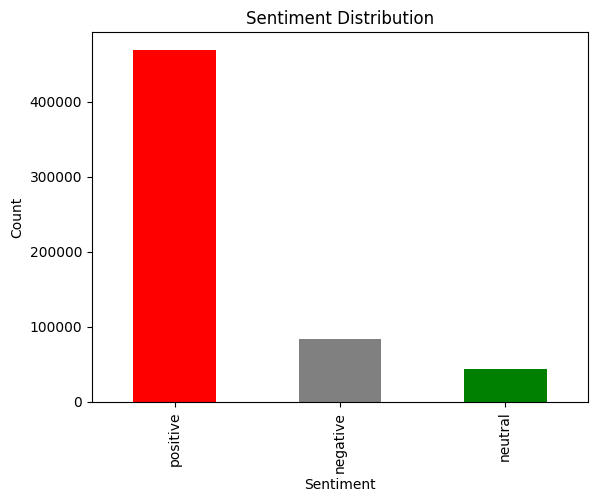

In [13]:
sentiment_counts = data['sentiment'].value_counts()
sentiment_counts.plot(kind='bar', color=['red', 'gray', 'green'])
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.show()


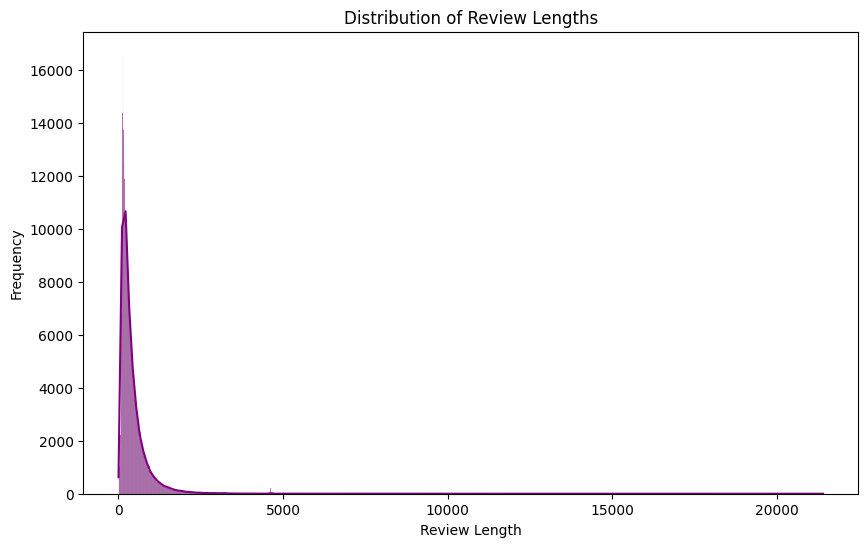

In [14]:
# Calculate the length of each review
data['review_length'] = data['review_text'].apply(len)

# Plotting the distribution of review lengths
plt.figure(figsize=(10, 6))
sns.histplot(data['review_length'], kde=True, color='purple')
plt.title('Distribution of Review Lengths')
plt.xlabel('Review Length')
plt.ylabel('Frequency')
plt.show()


<ipython-input-15-80c56af6425f>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sentiment', y='review_length', data=data, palette='Set2')


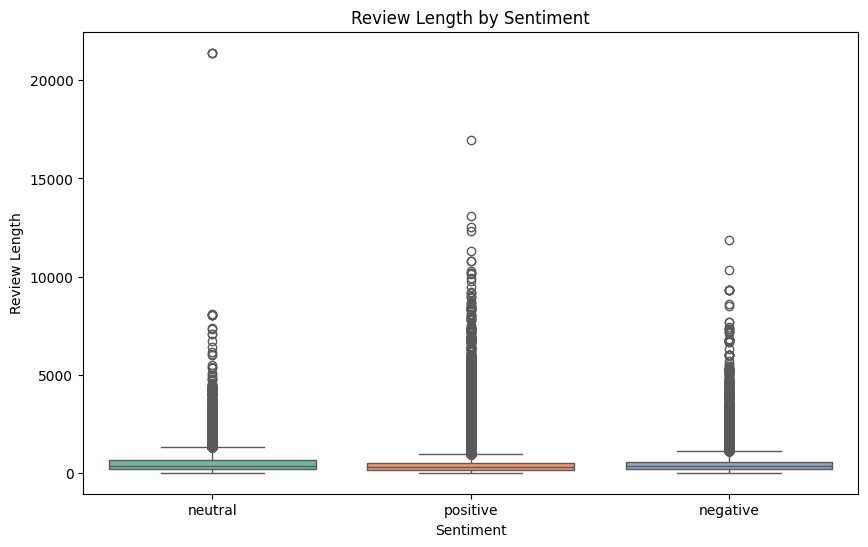

In [15]:
# Boxplot for review length by sentiment
plt.figure(figsize=(10, 6))
sns.boxplot(x='sentiment', y='review_length', data=data, palette='Set2')
plt.title('Review Length by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Review Length')
plt.show()


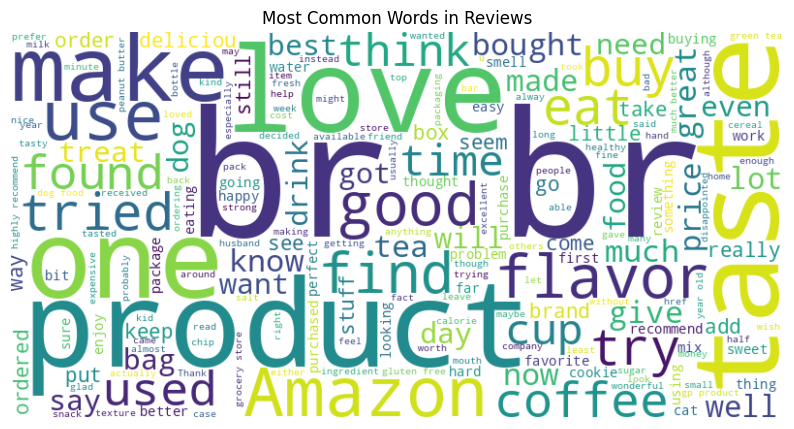

In [16]:
from wordcloud import WordCloud

# Combine all review texts into one string
all_reviews = ' '.join(data['review_text'])

# Generate the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_reviews)

# Plot the word cloud
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Reviews')
plt.show()


In [17]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)  # remove HTML
    text = re.sub(r'[^a-z\s]', '', text)  # keep only letters
    text = ' '.join(word for word in text.split() if word not in stop_words)
    return text

data['cleaned_text'] = data['review_text'].apply(clean_text)


In [18]:

sample_size = min(10000, len(data))
data = data.sample(n=sample_size, random_state=42).reset_index(drop=True)

In [19]:
print(data['sentiment'].value_counts())

sentiment
positive    7854
negative    1396
neutral      750
Name: count, dtype: int64


In [20]:
# Count sentiment class instances
class_counts = data['sentiment'].value_counts()
print("Class distribution:\n", class_counts)

# ✅ Keep only classes with at least 20 samples
valid_classes = class_counts[class_counts >= 20].index
filtered_data = data[data['sentiment'].isin(valid_classes)]

Class distribution:
 sentiment
positive    7854
negative    1396
neutral      750
Name: count, dtype: int64


In [21]:
# ✅ Balance by downsampling to the size of the smallest valid class
min_class_size = filtered_data['sentiment'].value_counts().min()

balanced_data = pd.concat([
    filtered_data[filtered_data['sentiment'] == sentiment].sample(min_class_size, random_state=42)
    for sentiment in valid_classes
])

# ✅ Shuffle and split the data
balanced_data = balanced_data.sample(frac=1, random_state=42).reset_index(drop=True)

X = balanced_data['cleaned_text']
y = balanced_data['sentiment']

# ✅ Train-test split (now each class has enough samples for stratification)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [22]:
tfidf = TfidfVectorizer(ngram_range=(1,2), max_df=0.95, min_df=5)

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(probability=True),
    "Random Forest": RandomForestClassifier()
}
results = {}

# Loop through the models
for name, model in models.items():
    # Create a pipeline with TF-IDF and the model
    pipe = Pipeline([('tfidf', tfidf), ('clf', model)])

    # Fit the model on the training data
    pipe.fit(X_train, y_train)

    # Predict on the test data
    y_pred_test = pipe.predict(X_test)

    # Calculate testing accuracy
 # Calculate testing accuracy
    test_acc = accuracy_score(y_test, y_pred_test)
    print(f"\n{name} - Testing Accuracy: {test_acc * 100:.2f}%")  # Print in percentage
    print(classification_report(y_test, y_pred_test))

    # Predict on the training data
    y_pred_train = pipe.predict(X_train)

    # Calculate training accuracy
    train_acc = accuracy_score(y_train, y_pred_train)
    results[name] = {"train_accuracy": train_acc, "test_accuracy": test_acc}

    print(f"{name} - Training Accuracy: {train_acc * 100:.2f}%")  # Print in percentage
    print("\n" + "-"*50)

# Print all results
print("\nAll model accuracies:")
for model_name, accuracy in results.items():
    print(f"{model_name} - Training Accuracy: {accuracy['train_accuracy'] * 100:.2f}%, Testing Accuracy: {accuracy['test_accuracy'] * 100:.2f}%")



Naive Bayes - Testing Accuracy: 59.56%
              precision    recall  f1-score   support

    negative       0.59      0.59      0.59       150
     neutral       0.51      0.53      0.52       150
    positive       0.70      0.66      0.68       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Naive Bayes - Training Accuracy: 86.44%

--------------------------------------------------

Logistic Regression - Testing Accuracy: 60.00%
              precision    recall  f1-score   support

    negative       0.58      0.63      0.61       150
     neutral       0.52      0.45      0.48       150
    positive       0.69      0.71      0.70       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Logistic Regression - Training Accuracy: 90.67%

---------


Naive Bayes - Testing Accuracy: 59.56%
              precision    recall  f1-score   support

    negative       0.59      0.59      0.59       150
     neutral       0.51      0.53      0.52       150
    positive       0.70      0.66      0.68       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Naive Bayes - Training Accuracy: 86.44%

--------------------------------------------------


<Figure size 1500x1000 with 0 Axes>

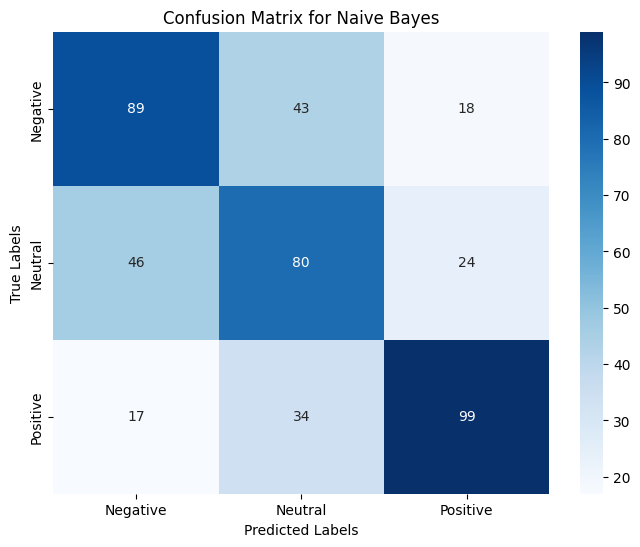

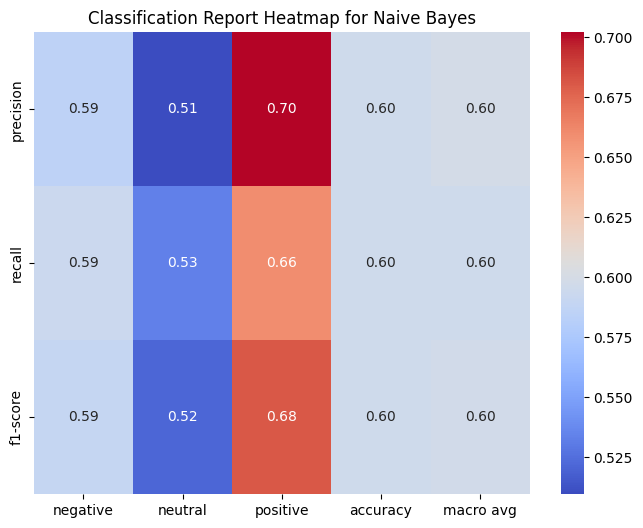


Logistic Regression - Testing Accuracy: 60.00%
              precision    recall  f1-score   support

    negative       0.58      0.63      0.61       150
     neutral       0.52      0.45      0.48       150
    positive       0.69      0.71      0.70       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Logistic Regression - Training Accuracy: 90.67%

--------------------------------------------------


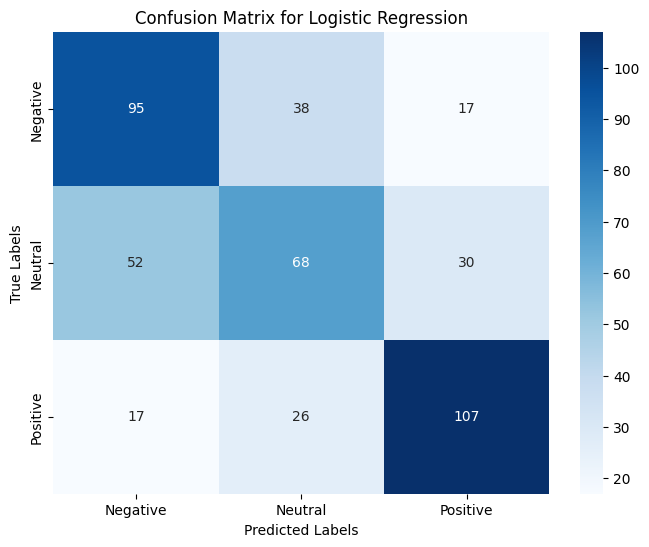

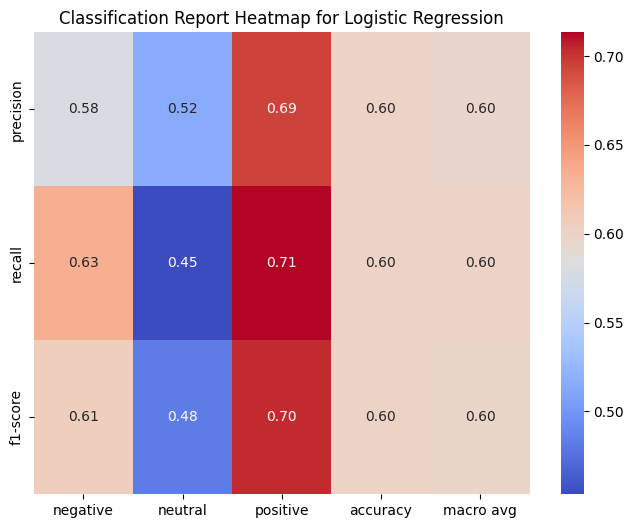


SVM - Testing Accuracy: 59.56%
              precision    recall  f1-score   support

    negative       0.58      0.61      0.59       150
     neutral       0.52      0.50      0.51       150
    positive       0.69      0.68      0.69       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

SVM - Training Accuracy: 99.50%

--------------------------------------------------


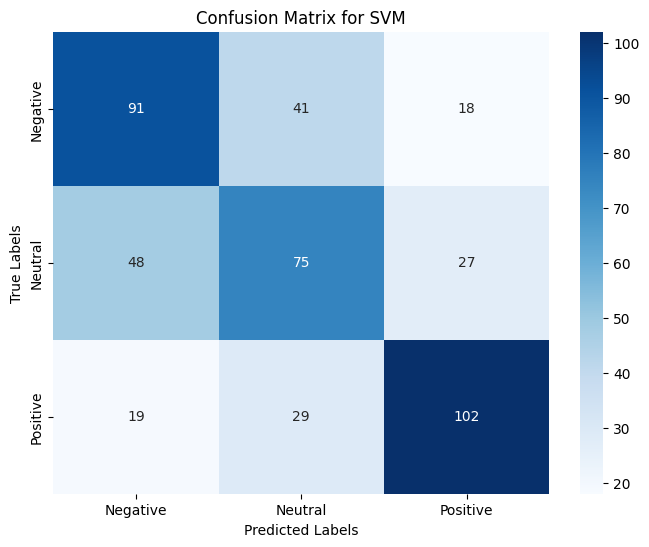

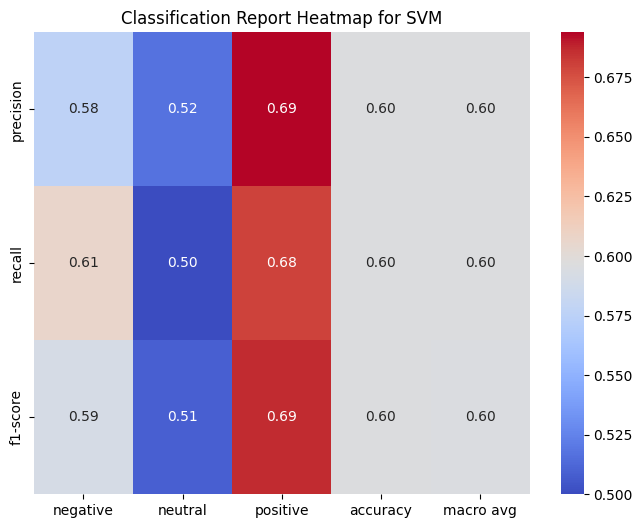


Random Forest - Testing Accuracy: 59.56%
              precision    recall  f1-score   support

    negative       0.55      0.61      0.58       150
     neutral       0.56      0.51      0.53       150
    positive       0.68      0.67      0.68       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Random Forest - Training Accuracy: 100.00%

--------------------------------------------------


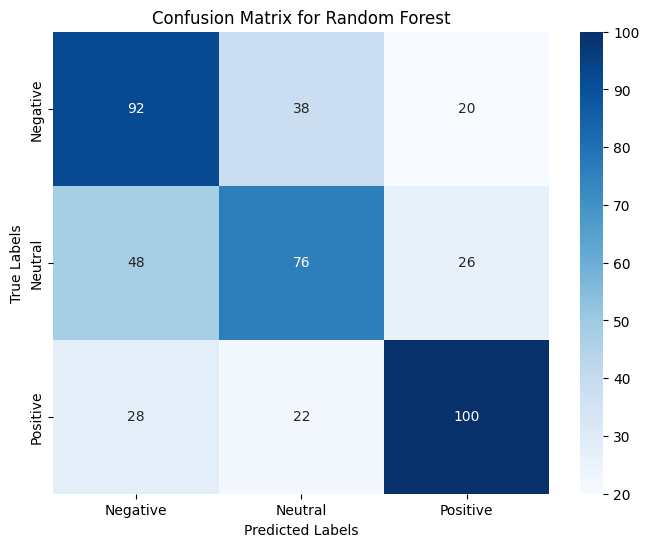

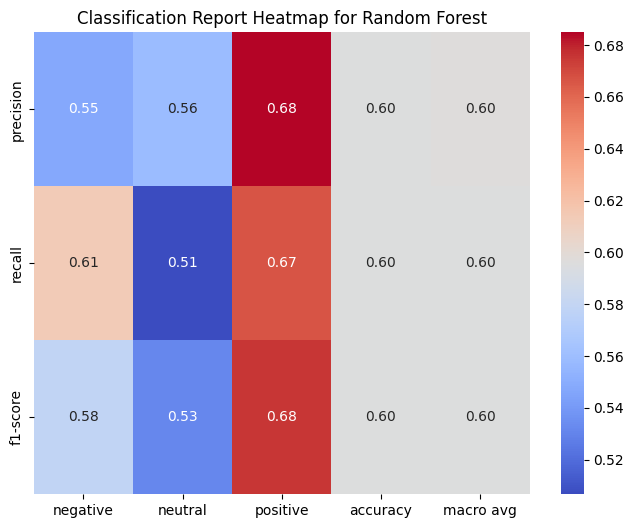

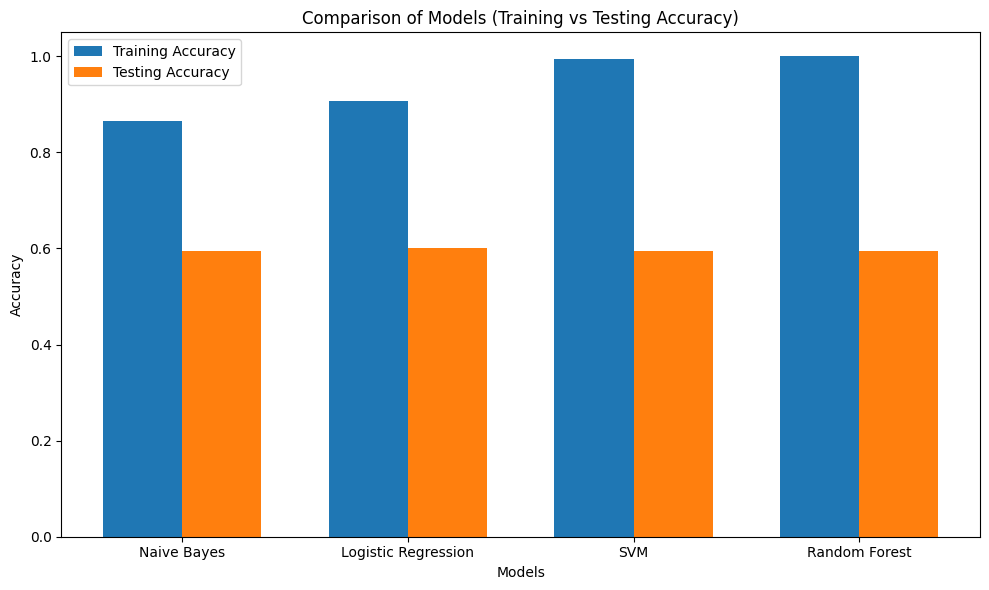

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Initialize the plot
plt.figure(figsize=(15, 10))

# Store the results for comparison
results = {}

# Loop through the models to evaluate performance and generate visualizations
for name, model in models.items():
    # Create a pipeline with the TF-IDF and the current model
    pipe = Pipeline([('tfidf', tfidf), ('clf', model)])

    # Fit the model on the training data
    pipe.fit(X_train, y_train)

    # Predict on the test data
    y_pred_test = pipe.predict(X_test)

    # Calculate testing accuracy
    test_acc = accuracy_score(y_test, y_pred_test)
    print(f"\n{name} - Testing Accuracy: {test_acc * 100:.2f}%")
    print(classification_report(y_test, y_pred_test))

    # Predict on the training data
    y_pred_train = pipe.predict(X_train)

    # Calculate training accuracy
    train_acc = accuracy_score(y_train, y_pred_train)
    results[name] = {"train_accuracy": train_acc, "test_accuracy": test_acc}

    print(f"{name} - Training Accuracy: {train_acc * 100:.2f}%")
    print("\n" + "-"*50)

    # **Visualization for Confusion Matrix**
    cm = confusion_matrix(y_test, y_pred_test)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
    plt.title(f'Confusion Matrix for {name}')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

    # **Classification Report Heatmap**
    report = classification_report(y_test, y_pred_test, output_dict=True)
    report_df = pd.DataFrame(report).iloc[:-1, :-1]  # Removing last row/column (accuracy)

    plt.figure(figsize=(8, 6))
    sns.heatmap(report_df, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title(f'Classification Report Heatmap for {name}')
    plt.show()

# **Visualize the Comparison of Models**
model_names = list(results.keys())
train_accs = [results[model]['train_accuracy'] for model in model_names]
test_accs = [results[model]['test_accuracy'] for model in model_names]

# Bar chart to compare training and testing accuracies for all models
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.35
index = np.arange(len(model_names))

bar1 = ax.bar(index, train_accs, bar_width, label='Training Accuracy')
bar2 = ax.bar(index + bar_width, test_accs, bar_width, label='Testing Accuracy')

ax.set_xlabel('Models')
ax.set_ylabel('Accuracy')
ax.set_title('Comparison of Models (Training vs Testing Accuracy)')
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(model_names)
ax.legend()

plt.tight_layout()
plt.show()


In [24]:
param_grids = {
    "Naive Bayes": {'clf__alpha': [0.01, 0.1, 1]},  # Smoothing parameter for Naive Bayes
    "Logistic Regression": {'clf__C': [0.1, 1, 10]},  # Regularization parameter for Logistic Regression
    "SVM": {'clf__C': [0.1, 1, 10], 'clf__kernel': ['linear', 'rbf']},  # Regularization & kernel for SVM
    "Random Forest": {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [5, 10, 15, 20],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4]
}}

# Store the original results (before tuning)
original_results = {}

# Loop through the models and record the original results
for name, model in models.items():
    print(f"Evaluating {name} without hyperparameter tuning...")

    # Create a pipeline with the TF-IDF and the current model
    pipe = Pipeline([('tfidf', tfidf), ('clf', model)])

    # Fit the model on the training data
    pipe.fit(X_train, y_train)

    # Predict on the test data
    y_pred_test = pipe.predict(X_test)

    # Calculate testing accuracy
    test_acc = accuracy_score(y_test, y_pred_test)
    print(f"{name} - Testing Accuracy (Original): {test_acc * 100:.2f}%")
    print(classification_report(y_test, y_pred_test))

    # Predict on the training data
    y_pred_train = pipe.predict(X_train)

    # Calculate training accuracy
    train_acc = accuracy_score(y_train, y_pred_train)

    # Store the original results
    original_results[name] = {"train_accuracy": train_acc, "test_accuracy": test_acc}

    print(f"{name} - Training Accuracy (Original): {train_acc * 100:.2f}%")
    print("\n" + "-"*50)

# Store the results of hyperparameter tuning
tuned_results = {}

# Loop through the models and perform hyperparameter tuning
for name, model in models.items():
    print(f"Starting hyperparameter tuning for {name}...")

    # Create a pipeline with the TF-IDF and the current model
    pipe = Pipeline([('tfidf', tfidf), ('clf', model)])

    # GridSearchCV for hyperparameter tuning
    grid_search = GridSearchCV(pipe, param_grids[name], cv=5, n_jobs=-1)

    # Fit the model on the training data
    grid_search.fit(X_train, y_train)

    # Get the best parameters and the best score
    best_params = grid_search.best_params_
    best_score = grid_search.best_score_

    # Print the best parameters and score from GridSearchCV
    print(f"Best Parameters: {best_params}")
    print(f"Best Cross-validation Score: {best_score * 100:.2f}%")

    # Predict on the test data using the best model
    y_pred_test = grid_search.predict(X_test)

    # Calculate testing accuracy
    test_acc = accuracy_score(y_test, y_pred_test)
    print(f"{name} - Testing Accuracy (Tuned): {test_acc * 100:.2f}%")
    print(classification_report(y_test, y_pred_test))

    # Predict on the training data using the best model
    y_pred_train = grid_search.predict(X_train)

    # Calculate training accuracy
    train_acc = accuracy_score(y_train, y_pred_train)

    # Store the tuned results
    tuned_results[name] = {"train_accuracy": train_acc, "test_accuracy": test_acc, "best_params": best_params}

    print(f"{name} - Training Accuracy (Tuned): {train_acc * 100:.2f}%")
    print("\n" + "-"*50)

# Print original and tuned results for comparison
print("\nComparison of Original and Tuned Results:")
for model_name in models.keys():
    print(f"{model_name}:")
    print(f"  Original - Training Accuracy: {original_results[model_name]['train_accuracy'] * 100:.2f}%, Testing Accuracy: {original_results[model_name]['test_accuracy'] * 100:.2f}%")
    print(f"  Tuned    - Training Accuracy: {tuned_results[model_name]['train_accuracy'] * 100:.2f}%, Testing Accuracy: {tuned_results[model_name]['test_accuracy'] * 100:.2f}%")
    print(f"  Tuned    - Best Hyperparameters: {tuned_results[model_name]['best_params']}")
    print("\n" + "-"*50)

Evaluating Naive Bayes without hyperparameter tuning...
Naive Bayes - Testing Accuracy (Original): 59.56%
              precision    recall  f1-score   support

    negative       0.59      0.59      0.59       150
     neutral       0.51      0.53      0.52       150
    positive       0.70      0.66      0.68       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Naive Bayes - Training Accuracy (Original): 86.44%

--------------------------------------------------
Evaluating Logistic Regression without hyperparameter tuning...
Logistic Regression - Testing Accuracy (Original): 60.00%
              precision    recall  f1-score   support

    negative       0.58      0.63      0.61       150
     neutral       0.52      0.45      0.48       150
    positive       0.69      0.71      0.70       150

    accuracy                           0.60       450
   macro avg    


Naive Bayes - Testing Accuracy (Original): 59.56%
              precision    recall  f1-score   support

    negative       0.59      0.59      0.59       150
     neutral       0.51      0.53      0.52       150
    positive       0.70      0.66      0.68       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Naive Bayes - Training Accuracy (Original): 86.44%

--------------------------------------------------


<Figure size 1500x1000 with 0 Axes>

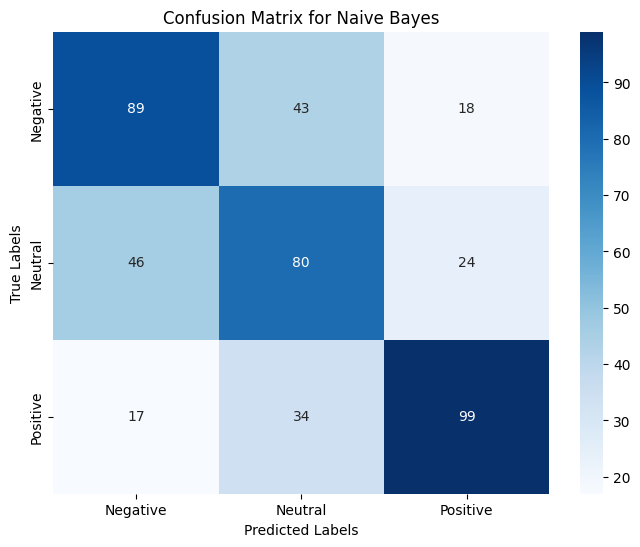

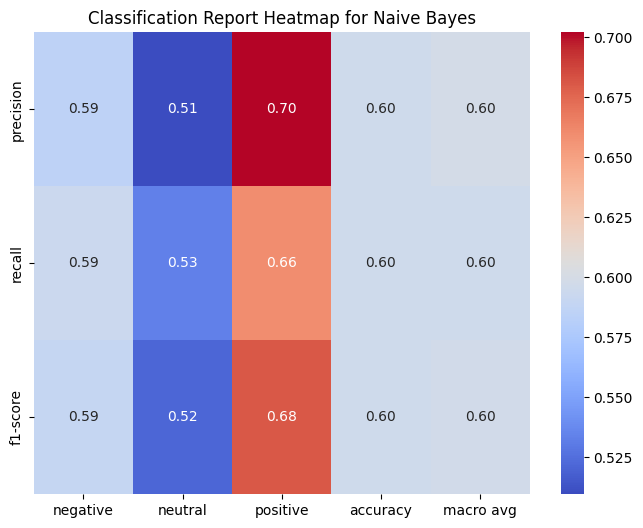


Logistic Regression - Testing Accuracy (Original): 60.00%
              precision    recall  f1-score   support

    negative       0.58      0.63      0.61       150
     neutral       0.52      0.45      0.48       150
    positive       0.69      0.71      0.70       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

Logistic Regression - Training Accuracy (Original): 90.67%

--------------------------------------------------


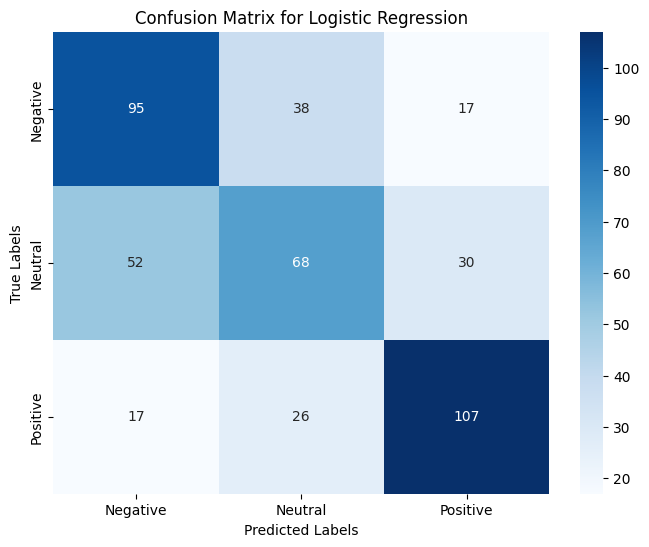

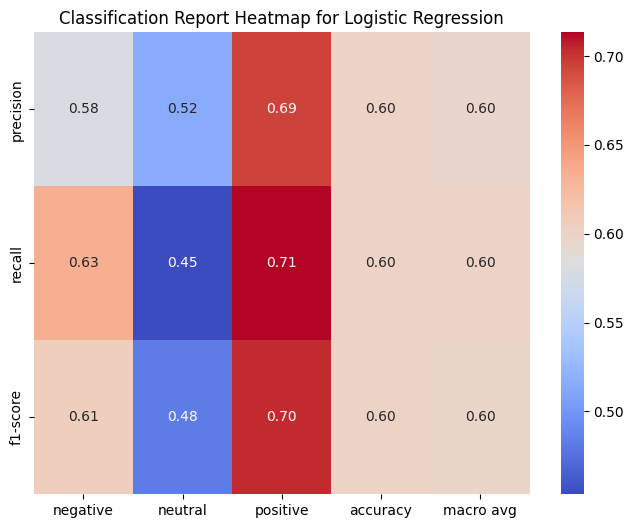


SVM - Testing Accuracy (Original): 59.56%
              precision    recall  f1-score   support

    negative       0.58      0.61      0.59       150
     neutral       0.52      0.50      0.51       150
    positive       0.69      0.68      0.69       150

    accuracy                           0.60       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.60      0.60      0.60       450

SVM - Training Accuracy (Original): 99.50%

--------------------------------------------------


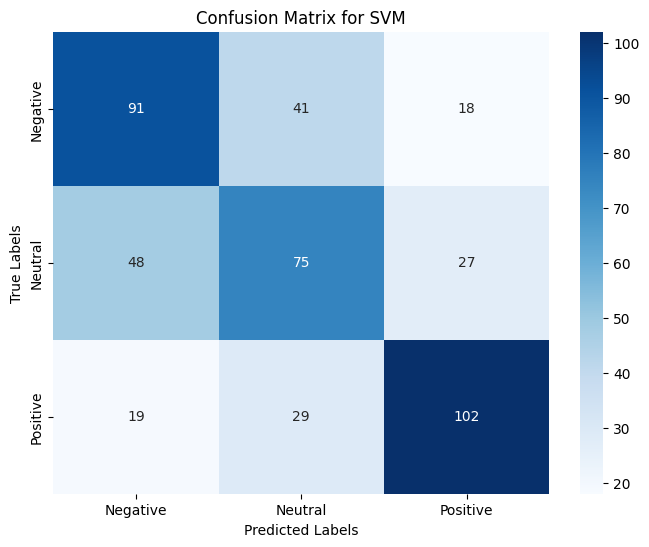

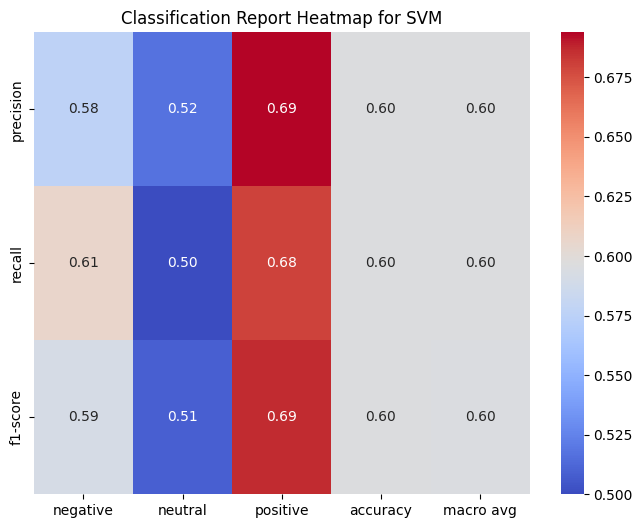


Random Forest - Testing Accuracy (Original): 57.33%
              precision    recall  f1-score   support

    negative       0.54      0.62      0.58       150
     neutral       0.52      0.47      0.49       150
    positive       0.66      0.63      0.65       150

    accuracy                           0.57       450
   macro avg       0.57      0.57      0.57       450
weighted avg       0.57      0.57      0.57       450

Random Forest - Training Accuracy (Original): 100.00%

--------------------------------------------------


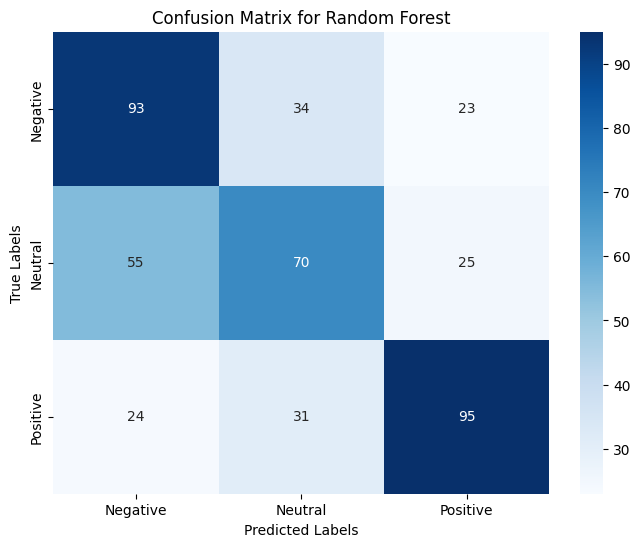

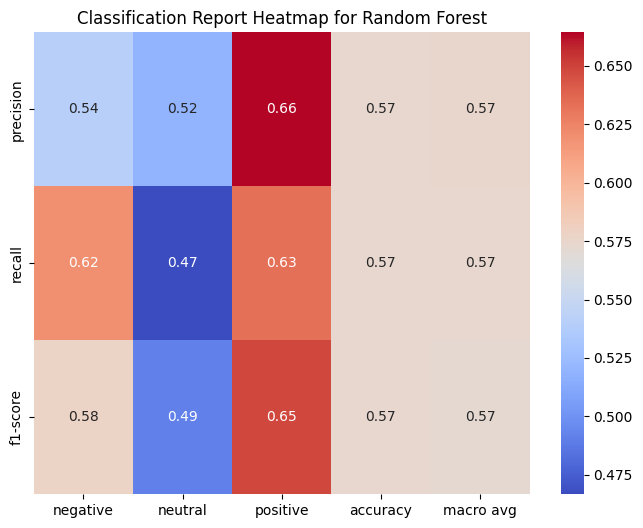

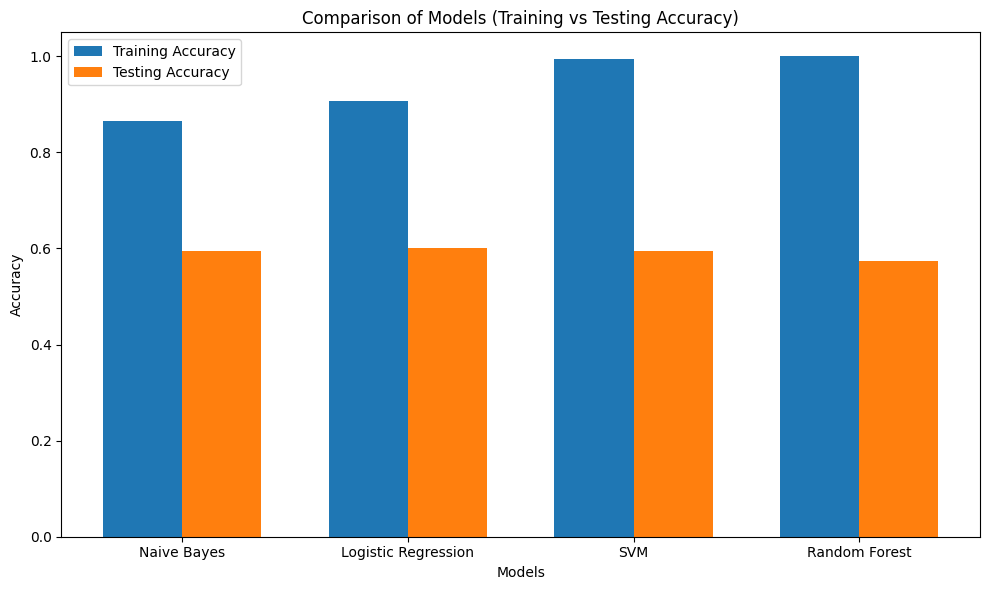

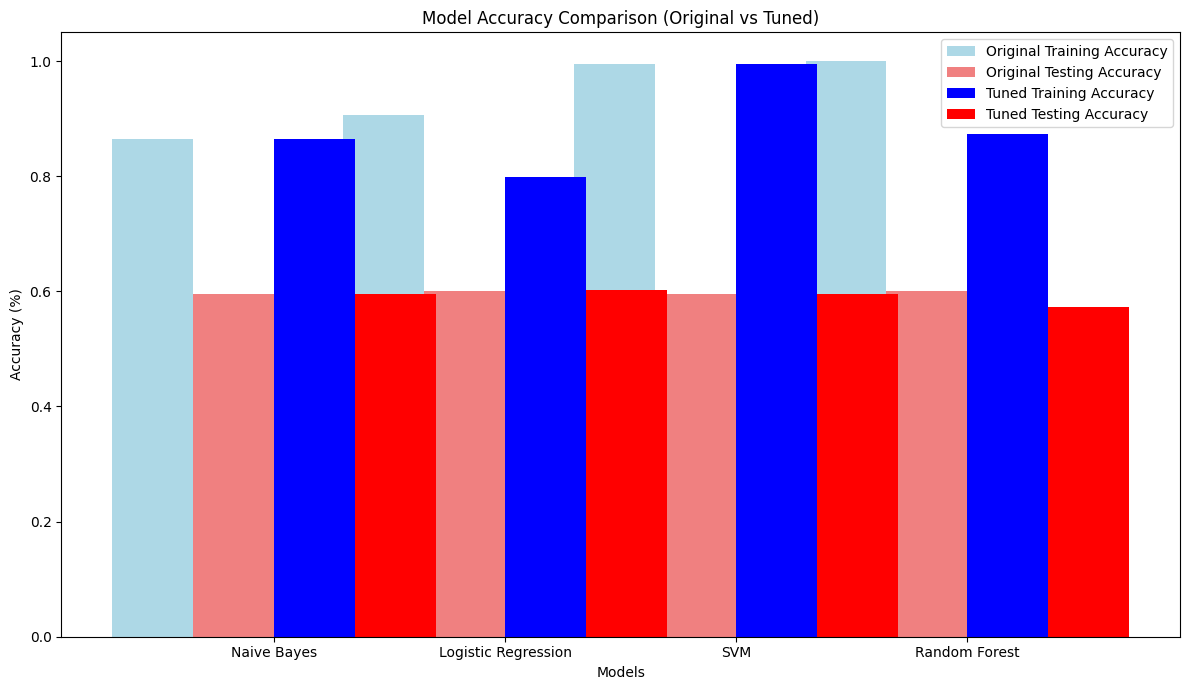

In [25]:
# Initialize the plot for model comparison
plt.figure(figsize=(15, 10))

# Store the results for comparison
results = {}

# Loop through the models to evaluate performance and generate visualizations
for name, model in models.items():
    # Create a pipeline with the TF-IDF and the current model
    pipe = Pipeline([('tfidf', tfidf), ('clf', model)])

    # Fit the model on the training data
    pipe.fit(X_train, y_train)

    # Predict on the test data
    y_pred_test = pipe.predict(X_test)

    # Calculate testing accuracy
    test_acc = accuracy_score(y_test, y_pred_test)
    print(f"\n{name} - Testing Accuracy (Original): {test_acc * 100:.2f}%")
    print(classification_report(y_test, y_pred_test))

    # Predict on the training data
    y_pred_train = pipe.predict(X_train)

    # Calculate training accuracy
    train_acc = accuracy_score(y_train, y_pred_train)
    results[name] = {"train_accuracy": train_acc, "test_accuracy": test_acc}

    print(f"{name} - Training Accuracy (Original): {train_acc * 100:.2f}%")
    print("\n" + "-"*50)

    # **Confusion Matrix Visualization**
    cm = confusion_matrix(y_test, y_pred_test)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Negative', 'Neutral', 'Positive'], yticklabels=['Negative', 'Neutral', 'Positive'])
    plt.title(f'Confusion Matrix for {name}')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.show()

    # **Classification Report Heatmap**
    report = classification_report(y_test, y_pred_test, output_dict=True)
    report_df = pd.DataFrame(report).iloc[:-1, :-1]  # Removing last row/column (accuracy)

    plt.figure(figsize=(8, 6))
    sns.heatmap(report_df, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title(f'Classification Report Heatmap for {name}')
    plt.show()

# **Visualize the Comparison of Models (before vs after tuning)**
model_names = list(results.keys())
train_accs = [results[model]['train_accuracy'] for model in model_names]
test_accs = [results[model]['test_accuracy'] for model in model_names]

# Bar chart to compare training and testing accuracies for all models
fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.35
index = np.arange(len(model_names))

bar1 = ax.bar(index, train_accs, bar_width, label='Training Accuracy')
bar2 = ax.bar(index + bar_width, test_accs, bar_width, label='Testing Accuracy')

ax.set_xlabel('Models')
ax.set_ylabel('Accuracy')
ax.set_title('Comparison of Models (Training vs Testing Accuracy)')
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(model_names)
ax.legend()

plt.tight_layout()
plt.show()

model_names = list(models.keys())
original_train_acc = [original_results[model]['train_accuracy'] for model in model_names]
original_test_acc = [original_results[model]['test_accuracy'] for model in model_names]
tuned_train_acc = [tuned_results[model]['train_accuracy'] for model in model_names]
tuned_test_acc = [tuned_results[model]['test_accuracy'] for model in model_names]

# Bar chart to compare training and testing accuracies (Original vs Tuned)
fig, ax = plt.subplots(figsize=(12, 7))

bar_width = 0.35
index = np.arange(len(model_names))

# Plotting the bars
bar1 = ax.bar(index, original_train_acc, bar_width, label='Original Training Accuracy', color='lightblue')
bar2 = ax.bar(index + bar_width, original_test_acc, bar_width, label='Original Testing Accuracy', color='lightcoral')
bar3 = ax.bar(index + 2 * bar_width, tuned_train_acc, bar_width, label='Tuned Training Accuracy', color='blue')
bar4 = ax.bar(index + 3 * bar_width, tuned_test_acc, bar_width, label='Tuned Testing Accuracy', color='red')

# Labeling the chart
ax.set_xlabel('Models')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Model Accuracy Comparison (Original vs Tuned)')
ax.set_xticks(index + 1.5 * bar_width)
ax.set_xticklabels(model_names)
ax.legend()

plt.tight_layout()
plt.show()


In [30]:
voting_clf = VotingClassifier(estimators=[
    ('lr', LogisticRegression(max_iter=1000)),
    ('rf', RandomForestClassifier()),
], voting='soft')

ensemble_pipe = Pipeline([
    ('tfidf', tfidf),
    ('clf', voting_clf)
])

ensemble_pipe.fit(X_train, y_train)
ensemble_pred = ensemble_pipe.predict(X_test)

print("\nVoting Classifier (Ensemble):\n")
print(classification_report(y_test, ensemble_pred))



Voting Classifier (Ensemble):

              precision    recall  f1-score   support

    negative       0.57      0.65      0.61       150
     neutral       0.57      0.51      0.54       150
    positive       0.71      0.69      0.70       150

    accuracy                           0.62       450
   macro avg       0.62      0.62      0.61       450
weighted avg       0.62      0.62      0.61       450




Voting Classifier (Ensemble):



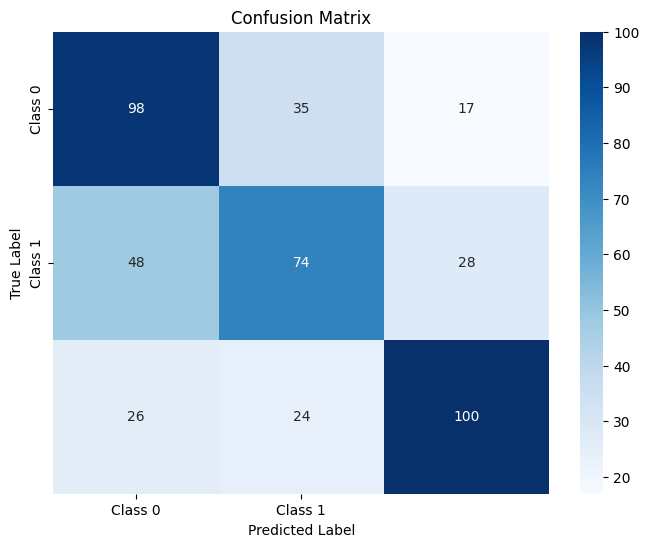

In [27]:
print("\nVoting Classifier (Ensemble):\n")

# Confusion Matrix
cm = confusion_matrix(y_test, ensemble_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [28]:
import joblib

# Assuming these are your trained objects
joblib.dump(model, 'voting_model.pkl')
joblib.dump(tfidf, 'vectorizer.pkl')

# Save a results dictionary (optional)
results = {
    "Naive Bayes": 0.70,
    "Logistic Regression": 0.72,
    "SVM": 0.73,
    "Random Forest": 0.71
}
joblib.dump(results, 'results.pkl')


['results.pkl']

In [29]:
from google.colab import files
files.download('voting_model.pkl')
files.download('vectorizer.pkl')
files.download('results.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>